In [1]:
print("My first E-commerce Customer Segmentation Project")

My first E-commerce Customer Segmentation Project


In [2]:
import pandas as pd

In [3]:
df = pd.read_excel("../data/online retail ii .xlsx")

FileNotFoundError: [Errno 2] No such file or directory: '../data/online retail ii .xlsx'

In [4]:
import os
print(os.getcwd())

C:\Users\anudh\Downloads\ecommerce-customer-segmentation\notebooks


In [5]:
import os

print(os.listdir("../data"))


['archive (1)']


In [6]:
import os

print(os.listdir("../data/archive (1)"))

['online_retail_II.xlsx']


In [10]:
df = pd.read_excel("../data/archive (1)/online_retail_II.xlsx")

KeyboardInterrupt: 

In [11]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [12]:
print(df.shape)


(525461, 8)


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 38.8+ MB


In [14]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [15]:
(df.isnull().sum() / len(df) * 100).round(2)

Invoice         0.00
StockCode       0.00
Description     0.56
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    20.54
Country         0.00
dtype: float64

In [16]:
df.duplicated().sum()

np.int64(6865)

In [17]:
df.drop_duplicates().shape

(518596, 8)

In [18]:
df_clean = df.drop_duplicates().copy()

print(df_clean.shape)

(518596, 8)


In [19]:
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107833
Country             0
dtype: int64

In [20]:
df_customers = df_clean.dropna(subset=["Customer ID"]).copy()

print(df_customers.shape)

(410763, 8)


In [21]:
print("Negative quantities:", (df_customers["Quantity"] < 0).sum())
print("Zero quantities:", (df_customers["Quantity"] == 0).sum())
print("Negative prices:", (df_customers["Price"] < 0).sum())

Negative quantities: 9816
Zero quantities: 0
Negative prices: 0


In [22]:
df_customers[df_customers["Quantity"] < 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [23]:
df_customers["Invoice"].astype(str).str.startswith("C").sum()

np.int64(9816)

In [24]:
df_purchases = df_customers[
    ~df_customers["Invoice"].astype(str).str.startswith("C")
].copy()

print(df_purchases.shape)

(400947, 8)


In [25]:
(df_purchases["Price"] == 0).sum()

np.int64(31)

In [26]:
df_purchases[df_purchases["Price"] == 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom


In [27]:
df_sales = df_purchases[df_purchases["Price"] > 0].copy()

print(df_sales.shape)

(400916, 8)


In [28]:
df_sales["Sales"] = df_sales["Quantity"] * df_sales["Price"]

df_sales[["Quantity", "Price", "Sales"]].head()

,Quantity,Price,Sales
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [29]:
(df_sales["Sales"] < 0).sum()

np.int64(0)

In [30]:
print("Earliest date:", df_sales["InvoiceDate"].min())
print("Latest date:", df_sales["InvoiceDate"].max())

Earliest date: 2009-12-01 07:45:00
Latest date: 2010-12-09 20:01:00


In [32]:
snapshot_date = df_sales["InvoiceDate"].max() + pd.Timedelta(days=1)

print(snapshot_date)

2010-12-10 20:01:00


In [33]:
last_purchase = df_sales.groupby("Customer ID")["InvoiceDate"].max()

print(last_purchase.head())

Customer ID
12346.0   2010-06-28 13:53:00
12347.0   2010-12-07 14:57:00
12348.0   2010-09-27 14:59:00
12349.0   2010-10-28 08:23:00
12351.0   2010-11-29 15:23:00
Name: InvoiceDate, dtype: datetime64[us]


In [34]:
recency = (snapshot_date - last_purchase).dt.days

print(recency.head())

Customer ID
12346.0    165
12347.0      3
12348.0     74
12349.0     43
12351.0     11
Name: InvoiceDate, dtype: int64


In [35]:
frequency = df_sales.groupby("Customer ID")["Invoice"].nunique()

print(frequency.head())

Customer ID
12346.0    11
12347.0     2
12348.0     1
12349.0     3
12351.0     1
Name: Invoice, dtype: int64


In [36]:
frequency = df_sales.groupby("Customer ID")["Invoice"].nunique()

print(frequency.head())

Customer ID
12346.0    11
12347.0     2
12348.0     1
12349.0     3
12351.0     1
Name: Invoice, dtype: int64


In [37]:
monetary = df_sales.groupby("Customer ID")["Sales"].sum()

print(monetary.head())

Customer ID
12346.0     372.86
12347.0    1323.32
12348.0     222.16
12349.0    2671.14
12351.0     300.93
Name: Sales, dtype: float64


In [38]:
rfm = pd.concat(
    [recency, frequency, monetary],
    axis=1
)

rfm.columns = ["Recency", "Frequency", "Monetary"]

print(rfm.head())

             Recency  Frequency  Monetary
Customer ID                              
12346.0          165         11    372.86
12347.0            3          2   1323.32
12348.0           74          1    222.16
12349.0           43          3   2671.14
12351.0           11          1    300.93


In [39]:
rfm.shape

(4312, 3)

In [40]:
rfm.describe()

,Recency,Frequency,Monetary
count,4312.000000,4312.000000,4312.000000
mean,91.171846,4.455705,2040.406712
std,96.860633,8.170213,8911.755977
min,1.000000,1.000000,2.950000
25%,18.000000,1.000000,307.187500
50%,53.000000,2.000000,701.615000
75%,136.000000,5.000000,1714.932500
max,374.000000,205.000000,349164.350000


In [41]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

print(rfm.head())

             Recency  Frequency  Monetary R_Score F_Score M_Score
Customer ID                                                      
12346.0          165         11    372.86       1       4       2
12347.0            3          2   1323.32       4       2       3
12348.0           74          1    222.16       2       1       1
12349.0           43          3   2671.14       3       3       4
12351.0           11          1    300.93       4       1       1


In [42]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm[["Recency", "Frequency", "Monetary", "RFM_Score"]].head())


             Recency  Frequency  Monetary RFM_Score
Customer ID                                        
12346.0          165         11    372.86       142
12347.0            3          2   1323.32       423
12348.0           74          1    222.16       211
12349.0           43          3   2671.14       334
12351.0           11          1    300.93       411


In [43]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm[["Recency", "Frequency", "Monetary", "RFM_Score"]].head())

             Recency  Frequency  Monetary RFM_Score
Customer ID                                        
12346.0          165         11    372.86       142
12347.0            3          2   1323.32       423
12348.0           74          1    222.16       211
12349.0           43          3   2671.14       334
12351.0           11          1    300.93       411


In [44]:
rfm["RFM_Score"].value_counts().head(10)

RFM_Score
444    454
111    339
344    213
121    170
333    169
233    160
211    142
433    140
112    138
222    125
Name: count, dtype: int64

In [45]:
def segment_customer(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "At Risk"
    else:
        return "Regular Customers"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print(rfm[["R_Score", "F_Score", "M_Score", "Segment"]].head())

            R_Score F_Score M_Score            Segment
Customer ID                                           
12346.0           1       4       2  Regular Customers
12347.0           4       2       3  Regular Customers
12348.0           2       1       1            At Risk
12349.0           3       3       4    Loyal Customers
12351.0           4       1       1  Regular Customers


In [46]:
rfm["Segment"].value_counts()

Segment
At Risk              1452
Loyal Customers      1452
Regular Customers    1408
Name: count, dtype: int64

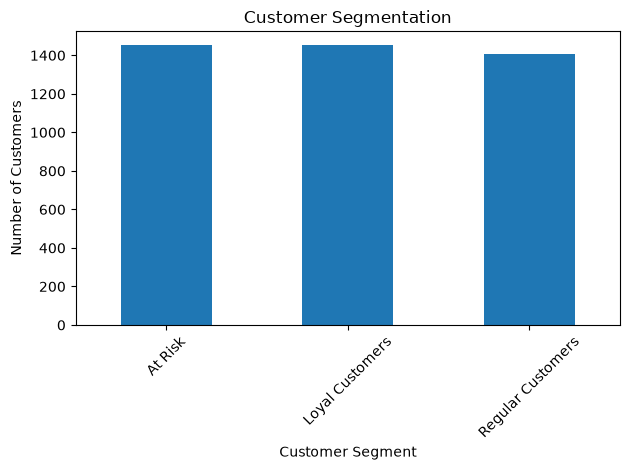

In [47]:
import matplotlib.pyplot as plt

rfm["Segment"].value_counts().plot(kind="bar")

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
# Save original dataset
df.to_csv("../data/raw_transactions.csv", index=False)

# Save cleaned transaction data
df_sales.to_csv("../data/cleaned_transactions.csv", index=False)

# Save customer segmentation results
rfm.reset_index().to_csv(
    "../data/customer_rfm_segments.csv",
    index=False
)

print("All 3 CSV files saved successfully!")

All 3 CSV files saved successfully!


In [49]:
import os

files = [
    "../data/raw_transactions.csv",
    "../data/cleaned_transactions.csv",
    "../data/customer_rfm_segments.csv"
]

for file in files:
    print(file, "->", os.path.exists(file))

../data/raw_transactions.csv -> True
../data/cleaned_transactions.csv -> True
../data/customer_rfm_segments.csv -> True


In [1]:

# Prepare customer segmentation data for SQL
rfm_export = rfm.reset_index()

# Convert customer IDs to whole numbers
rfm_export["Customer ID"] = (
    rfm_export["Customer ID"].astype("int64")
)

# Save the corrected CSV
rfm_export.to_csv(
    "../data/customer_rfm_segments.csv",
    index=False
)

print("Customer CSV prepared for PostgreSQL!")


NameError: name 'rfm' is not defined

In [2]:
import pandas as pd

rfm_export = pd.read_csv("../data/customer_rfm_segments.csv")

print(rfm_export.shape)
print(rfm_export.columns.tolist())
rfm_export.head()

(4312, 9)
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment']


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,165,11,372.86,1,4,2,142,Regular Customers
1,12347.0,3,2,1323.32,4,2,3,423,Regular Customers
2,12348.0,74,1,222.16,2,1,1,211,At Risk
3,12349.0,43,3,2671.14,3,3,4,334,Loyal Customers
4,12351.0,11,1,300.93,4,1,1,411,Regular Customers


In [3]:
rfm_export["Customer ID"] = (
    rfm_export["Customer ID"].astype("int64")
)

rfm_export.to_csv(
    "../data/customer_rfm_segments.csv",
    index=False
)

print("Customer CSV is ready for SQL!")

Customer CSV is ready for SQL!


In [4]:

import os

file_path = "../data/cleaned_transactions.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size (MB):", round(
        os.path.getsize(file_path) / (1024 * 1024), 2
    ))


File exists: True
File size (MB): 37.94


In [5]:

import pandas as pd

transactions_export = pd.read_csv(
    "../data/cleaned_transactions.csv"
)

print("Shape:", transactions_export.shape)
print("Columns:", transactions_export.columns.tolist())
print(transactions_export["Customer ID"].head())


Shape: (400916, 9)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Sales']
0    13085.0
1    13085.0
2    13085.0
3    13085.0
4    13085.0
Name: Customer ID, dtype: float64


In [6]:

# Convert customer IDs to whole numbers
transactions_export["Customer ID"] = (
    transactions_export["Customer ID"].astype("int64")
)

# Save the corrected file
transactions_export.to_csv(
    "../data/cleaned_transactions.csv",
    index=False
)

print("Transaction CSV prepared for PostgreSQL!")


Transaction CSV prepared for PostgreSQL!
